# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [2]:
patients = pd.read_csv(PATIENTS_PATH)  # TODO: read PATIENTS_PATH with pd.read_csv

# TODO: print the shape and the dtypes of patients
print(patients.shape)
(display(patients.dtypes))


exploratory_chart = alt.Chart(patients).mark_point(filled=True, size=40, opacity=0.6).encode(
    x= alt.X('sessions_attended:Q', title='Sessions attended (of 36)', scale=alt.Scale(zero=False)),
    y= alt.Y('walk_distance_m:Q', title='Six-minute walk distance (m)', scale=alt.Scale(zero=False)),
    color=alt.Color('program:N'),
    shape=alt.Shape('program:N'),

    tooltip=[
        alt.Tooltip('patient_id:N', title='Patient ID'),
        alt.Tooltip('sessions_attended:Q', title='Sessions attended (of 36)'),
        alt.Tooltip('walk_distance_m:Q', title='Six-minute walk distance (m)')
    ],
).properties(title='Exploratory scatter plot of sessions attended vs walk distance', width=320, height=260).interactive()


  # TODO: the Altair scatter plot README Task 1.1 describes

# TODO: save exploratory_chart to EXPLORATORY_SPEC_PATH with .save()
exploratory_chart.save(EXPLORATORY_SPEC_PATH, index=False)

exploratory_chart

(12, 4)


patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object

alt.Chart(...)

### 1.2 Describe what the chart shows

The chart compares the sessions attended to how far of a distance is walked within 6 minutes (and measured in meters). When looking at one of the points, you will see each patient's stats, as well as their ID. The chart is suggesting a positive correlation between more sessions and more distance walked. It is hard to determine from a smaller sample group, such as 12 patients, that attending more sessions equals longer walking distances. There could be other factors determining a patient's ability to walk faster or slower. The patients joining this cardiac rehabilitation service have experienced various procedures or medical events, and they would all be impacted very differently during recovery.

## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


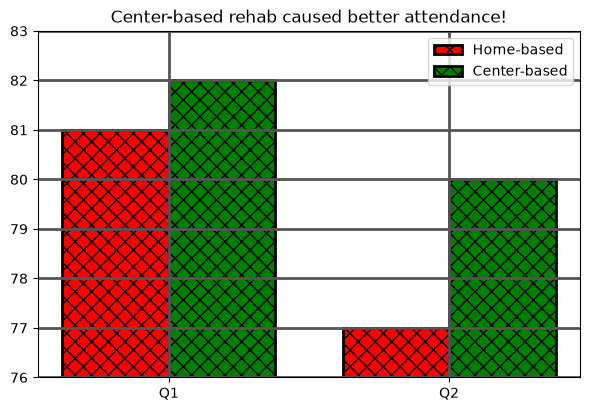

In [3]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [4]:
critique = [
    {"category": "unsupported claim", "problem": "The title makes an immediate claim about the effectiveness of center-based rehab leading to better attendance", "repair": "Use a title that reflects the data being shown, that the home-based and center-based rehab attendances were shown by quarter 1 and quarter 2"},  # TODO: fill in each problem and repair
    
    {"category": "truncated baseline", "problem": "The y-axis should start at 0 to make the chart more visually accurate", "repair": "Make the y-axis start from 0"},
    
    {"category": "missing unit", "problem": "The y-axis label is missing so we do not know exactly what data is being represented", "repair": "Include the correct y-axis label"},
    
    {"category": "color-only encoding", "problem": "The home-based and center-based rehab encoding need to be in color only", "repair": "Two colors that can be distinguishable in grey-scale but also friendly for color-blind people, for the home-based and center-based rehab, respectively"},
    
    {"category": "distracting decoration", "problem": "The criss-cross design is shared for both rehabs, the grid lines that lay ontop of the bars, and the corner of the bottom bars that cross into the white space are all distracting and look messy", "repair": "Clean up the extra lines, and choose a distinguishable pattern for each rehab"},
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: The title makes an immediate claim about the effectiveness of center-based rehab leading to better attendance
    repair: Use a title that reflects the data being shown, that the home-based and center-based rehab attendances were shown by quarter 1 and quarter 2
truncated baseline: The y-axis should start at 0 to make the chart more visually accurate
    repair: Make the y-axis start from 0
missing unit: The y-axis label is missing so we do not know exactly what data is being represented
    repair: Include the correct y-axis label
color-only encoding: The home-based and center-based rehab encoding need to be in color only
    repair: Two colors that can be distinguishable in grey-scale but also friendly for color-blind people, for the home-based and center-based rehab, respectively
distracting decoration: The criss-cross design is shared for both rehabs, the grid lines that lay ontop of the bars, and the corner of the bottom bars that cross into the white space are 

### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

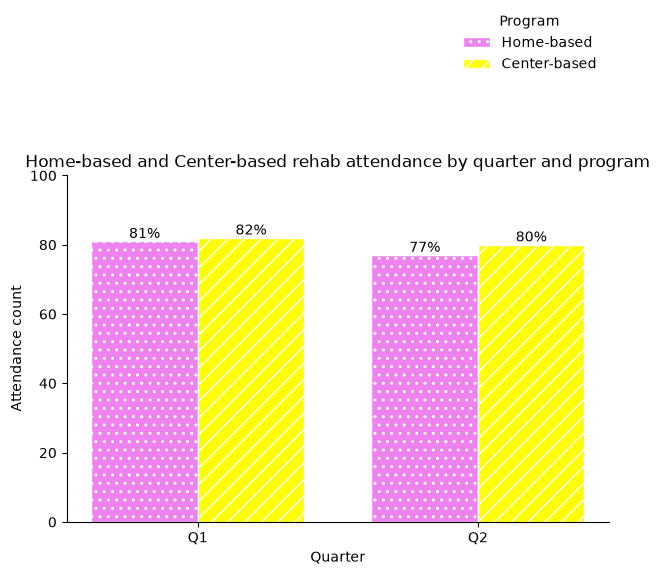

y-axis runs from 0.0 to 100.0


In [ ]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

# TODO: draw the four bars again from home and center on redesign_ax, repairing each problem in your critique
# (README Task 2.3 lists the repairs)

home_bar = redesign_ax.bar(x - width / 2, home, width, label='Home-based',
                       color='violet', hatch='..', edgecolor='white')
center_bar = redesign_ax.bar(x + width / 2, center, width, label='Center-based',
                              color='yellow', hatch='//', edgecolor='white')

home_label = redesign_ax.bar_label(home_bar, fmt='%d%%')
center_label = redesign_ax.bar_label(center_bar, fmt='%d%%')



redesign_ax.set_xticks(x, quarters)
redesign_ax.set(ylim=(0, 100), xlabel='Quarter', ylabel='Attendance count')

redesign_ax.set_title("Home-based and Center-based rehab attendance by quarter and program")
redesign_ax.spines[['top', 'right']].set_visible(False)
redesign_ax.le/.   ,gend(title='Program', loc='upper right', bbox_to_anchor=(1, 1.5), frameon=False)
plt.show()





# TODO: save redesign_fig to REDESIGN_PATH with dpi=150 and bbox_inches="tight"

redesign_fig.savefig(REDESIGN_PATH, dpi=150, bbox_inches="tight")

plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [6]:
followup = pd.read_csv(FOLLOWUP_PATH)

display(followup)
# TODO: read FOLLOWUP_PATH with pd.read_csv
# TODO: display followup


question = "Looking into the two quarters, how was the home-based attendance compared to center-based attendance"  # TODO: the comparison the chart should help the coordinator make
audience = "The rehab facilitators/hospital management; they would want to study and compare the effectiveness of each program type"  # TODO: who reads the chart and what they will use it for
intended_claim = "Both quarters reflect that center-based rehab is attended more, but only by a slight margin"  # TODO: the one descriptive conclusion the chart supports
y_measure = "Measures the amount of participants in attendance for the rehab programs"  # TODO: what the y-axis measures, with its unit
grain = "One source row per percent of attendance; one histogram bar per program"  # TODO: what one row of the plotting table and one point on a line represent
data_types = {
    "program": "categorical",  # TODO: categorical, quantitative, ordinal, or temporal
    "visit_number": "ordinal",  # TODO
    "goal_met_pct": "quantitative",  # TODO
}

supporting_data = followup[["program", "visit_number", "goal_met_pct"]]

  # TODO: the three plotted columns of followup


supporting_data.to_csv(SUPPORTING_DATA_PATH, index=False)
# TODO: save supporting_data to SUPPORTING_DATA_PATH without the row index

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

,program,visit_number,patients_seen,goal_met_pct
0,Home-based,1,48,58
1,Home-based,2,46,63
2,Home-based,3,45,67
3,Home-based,4,44,70
4,Center-based,1,52,57
5,Center-based,2,50,65
6,Center-based,3,49,72
7,Center-based,4,47,79


shape: (8, 3)
same as saved: True


### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

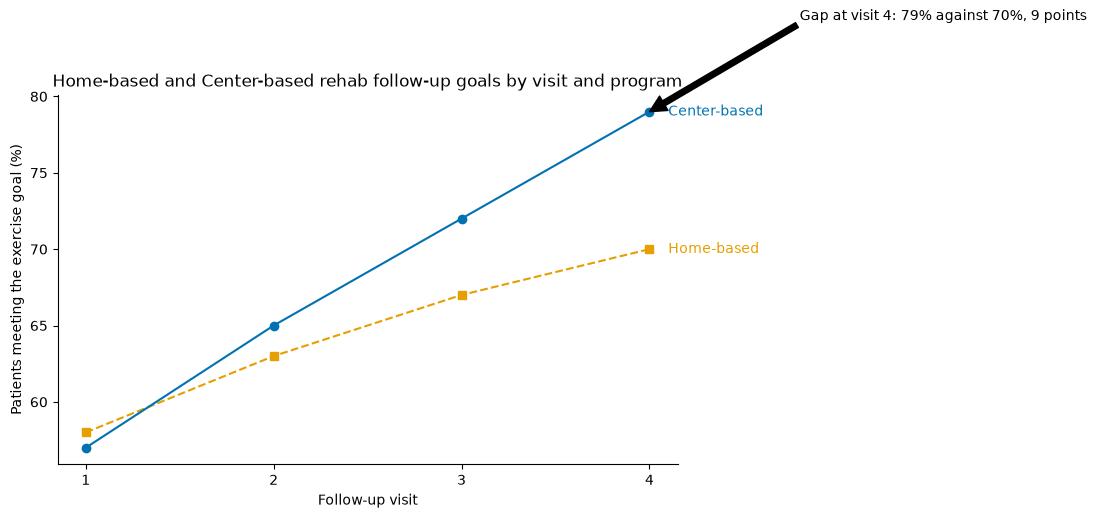

In [7]:
home_goals = supporting_data.loc[supporting_data["program"] == "Home-based"]
center_goals = supporting_data.loc[supporting_data["program"] == "Center-based"]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))


# TODO: draw one line per program on explanatory_ax, with visit_number on x and goal_met_pct on y,
# and finish the chart as README Task 3.2 describes
#visit_number on x and goal_met_pct on y;
#each program with its own color, marker, and line style, such as ORANGE, 's', and '--' for Home-based and BLUE, 'o', and '-' for Center-based, named by a direct label at its right end or by a legend;
#one annotation whose arrow points to Center-based's visit-4 point, (4, 79), and whose text states the gap at visit 4: 79% against 70%, 9 points;
#axis labels with units, such as Follow-up visit and Patients meeting the exercise goal (%), ticks at visits 1 to 4, and a title that states the finding without claiming a cause;
#the top and right spines hidden.
explanatory_ax.plot(home_goals["visit_number"], home_goals["goal_met_pct"], color=ORANGE, marker='s', linestyle='--', label='Home-based')
explanatory_ax.plot(center_goals["visit_number"], center_goals["goal_met_pct"], color=BLUE, marker='o', linestyle='-', label='Center-based')
explanatory_ax.text(4.1, 79, "Center-based", color=BLUE, fontsize=10, verticalalignment='center')
explanatory_ax.text(4.1, 70, "Home-based", color=ORANGE, fontsize=10, verticalalignment='center')
explanatory_ax.annotate("Gap at visit 4: 79% against 70%, 9 points", xy=(4, 79), xytext=(4.8, 85),
                        arrowprops=dict(facecolor='black', shrink=0.0))
explanatory_ax.set_xlabel("Follow-up visit")
explanatory_ax.set_ylabel("Patients meeting the exercise goal (%)")
explanatory_ax.set_xticks([1, 2, 3, 4])
explanatory_ax.set_title("Home-based and Center-based rehab follow-up goals by visit and program")
explanatory_ax.spines[['top', 'right']].set_visible(False)


# TODO: save explanatory_fig to EXPLANATORY_PATH with dpi=150 and bbox_inches="tight"
explanatory_fig.savefig(EXPLANATORY_PATH, dpi=150, bbox_inches="tight")

plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [8]:
text_alternative = "The chart created is a line plot, illustrating the number of follow-up visits for each program type, and comparing it to the exercise goals met by participants. The x-axis represents the number of sessions completed, while the y-axis is the percentage of participants meeting the exercise goal. The Home-based program showed an increase from 58% at visit 1 to 70% at visit 4, while the center-based program was 58% at visit 1 to 79% at visit 4, which is a 9% difference. But because it was the participant's choice which program they wanted to participate in, this does not necessarily mean the center-based program causes participants to meet their exercise goals more. The difference could also not be accounting for those who chose to drop out from the programs.  "  # TODO: one paragraph, as README Task 3.3 describes

visualization_evidence = {
    "critique": critique,
    "question": question,
    "audience": audience,
    "intended_claim": intended_claim,
    "y_measure": y_measure,
    "grain": grain,
    "data_types": data_types,
    "text_alternative": text_alternative
    # TODO: add question, audience, intended_claim, y_measure, grain, data_types, and text_alternative
}

# TODO: save visualization_evidence to EVIDENCE_PATH with json.dump, as the Task 2.2 cell does
with open (EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump(visualization_evidence, file, indent=2, ensure_ascii=False)



# TODO: write text_alternative to TEXT_ALTERNATIVE_PATH

with open (TEXT_ALTERNATIVE_PATH, "w", encoding="utf-8") as file:
    file.write(text_alternative)

with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

['critique', 'question', 'audience', 'intended_claim', 'y_measure', 'grain', 'data_types', 'text_alternative']


### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.


1. The darker color would reflect the purple, and the lighter color would reflect the yellow, so it's important to make one color darker and the other color lighter so when printed in greyscale, it shows how bright the color is. Also, having different hatch patterns help distinguish the two.

2. The annotation points to the fourth visit of the center-based program, and it is clarifying the gap of 9 points, which is important to identify and to clear up that the difference does not conclude the center-based program is better than the home-based from this alone.

3. Initially, the arrow was crossing over with the title, so I adjusted the explanatory_ax.annotate part, specifically xy=(4, 79) and xytext=(4.8, 85), making it 4 and 4.9 for the x values, so that the text it was pointing to wasn't too far away, and that the arrow didn't cross over any text.

4. The main limitation of this is that participants chose which program to participate in. Because they were not randomly assigned, it makes it difficult to conclude that any one program is better than the other, and there could be other factors causing fewer participants to show up for their final visit.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [9]:
from check_assignment import run_checks

_ = run_checks()

Checks: latest from the course repository (main).
[PASS]  4/4  exploratory spec: point mark
[PASS]  5/5  exploratory spec: embedded patient rows
[PASS]  4/4  exploratory spec: x encoding
[PASS]  4/4  exploratory spec: y encoding
[PASS]  4/4  exploratory spec: color encoding
[PASS]  4/4  exploratory spec: shape encoding
[PASS] 12/12 critique redesign: PNG image
[PASS]  5/5  critique: unsupported claim
[PASS]  5/5  critique: truncated baseline
[PASS]  5/5  critique: missing unit
[PASS]  5/5  critique: color-only encoding
[PASS]  5/5  critique: distracting decoration
[PASS]  8/8  explanatory chart: PNG image
[PASS]  4/4  supporting data: columns
[PASS]  6/6  supporting data: rows and values
[PASS]  2/2  evidence: question
[PASS]  2/2  evidence: audience
[PASS]  2/2  evidence: intended_claim
[PASS]  2/2  evidence: y_measure
[PASS]  2/2  evidence: grain
[PASS]  2/2  evidence: text_alternative
[PASS]  2/2  data type: program
[PASS]  2/2  data type: visit_number
[PASS]  2/2  data type: goal_m